# Per-mite, centre-based plate shake correction

**The question:** would moving each mite's patch back by **its own centre's** shift work as well as moving every patch back by **the plate's** shift (the median over all mites of their phase correlation + ECC shifts), what the app did until 16 October 2026?

The per-mite centre method is the one of commit `2439dca` (branch `backup/before-revert-2026-10-14`): a mite's shift is how far the centre of the darkness of its body moved from the first frame. It was reverted on 14 October with everything per-mite. This report was made before it came back, and on its findings it is what `classes/plate_stabilizer.py` does since 16 October (with a mite's shift followed up to 12 px, and a mite whose centre can't be found taking the median of the others'; neither happens on these recordings). The benchmark keeps the plate's ECC measurement as it was (`ecc_shifts()` in `scripts/centre_stabilization.py`).

Five ways of cutting the patch the score (`outline_variability`) is computed on:

| method | the patch is moved back by |
|---|---|
| `none` | nothing (stabilization off) |
| `plate_ecc` | the plate's shift: median over all mites of their phase correlation + ECC shifts. **What the app did until 16 October 2026.** |
| `plate_centre` | the median over all mites of their centres' shifts |
| `own_centre` | the mite's own centre's shift. **The proposal; what the app does since.** |
| `own_ecc` | the mite's own phase correlation + ECC shift |

**Data:** every labelled (mite, recording) of the four recording folders with ground truth, read from their saved ROI videos. The recordings were made on a still plate, so the shake is synthetic, made as a camera would see it (enlarged 4x, moved by whole enlarged pixels, averaged back): per frame a random offset with a standard deviation of 0.5, 1 or 2 px, either the same for every mite (**rigid**: the holder shakes) or one per plate (**per plate**: each of the 15 plates shakes on its own, as `plate_shake.ipynb` on the backup branch saw the zones move apart by up to 0.85 px at 1.3 h of the long run). Every method sees the same shaken frames.

**Two cautions.**

- The long run's labels were saved as the calls of the score in use (`outline_variability` with the plate's method), so on that run "against the labels" favours `plate_ecc` by construction. It is reported separately, and the long run is judged mainly on how many of its 16 000 still recordings get called moving.
- The threshold is the one in `config.default.yaml`, calibrated with `plate_ecc` on unshaken recordings. Each method is also given its own best threshold (Youden's J) on the unshaken hand-labelled data, so a method is not penalised only for sitting on a slightly different scale.

`python scripts/centre_stabilization.py` makes the table this notebook reads (about 20 min on 8 processes); before the switch, its unshaken `none` and `plate_ecc` scores equalled the app's (`pipeline.calibration.score_cache.score_mites`) on sample_data to the last digit, and after it, the app's equal its `own_centre` on all 17 829 observations.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("DISCOBOX_CONFIG", str(ROOT / "config.default.yaml"))  # the defaults, only read
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes import calibration
from classes.app_config import METRIC, get_default_config
from centre_stabilization import METHODS, OUT, SHAKES
METHODS = list(METHODS)

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

THRESHOLD = get_default_config().mite.threshold_for(METRIC)
LONG = "test_run_2026-09-08_Mathis_last_dsRNA"
SHAKE_ORDER = [name for name, *_ in SHAKES]
STABILIZED = [m for m in METHODS if m != "none"]
# a fixed colour per method; "none" is the grey baseline
COLOURS = {"none": "#8a8984", "plate_ecc": "#2a78d6", "own_centre": "#eb6834", "plate_centre": "#1baf7a", "own_ecc": "#eda100"}
STYLE = {"none": "--"}
MARKER = {"none": "o", "plate_ecc": "o", "plate_centre": "s", "own_centre": "D", "own_ecc": "^"}  # tells overlapping lines apart
SIZE = {"none": 5, "plate_ecc": 9, "plate_centre": 5, "own_centre": 9, "own_ecc": 5}

table = pd.read_csv(OUT, dtype={"mite": str})  # ids like 4.10 must stay strings
table["shake"] = pd.Categorical(table["shake"], SHAKE_ORDER, ordered=True)
table["group"] = np.where(table["dataset"] == LONG, "long run (labels = calls)", "hand-labelled (3 short runs)")
still = table[table["shake"] == "still"]

print(f"OpenCV {cv2.__version__}, {METRIC} threshold {THRESHOLD}")
still.groupby("dataset").agg(mites=("mite", "nunique"), recordings=("recording", "nunique"),
                             moving=("moving", "sum"), observations=("moving", "size"))

OpenCV 4.12.0, outline_variability threshold 1.638


,mites,recordings,moving,observations
dataset,,,,
ground_truth_60min,29,6,78,174
ground_truth_90min,28,6,71,168
sample_data,29,6,76,173
test_run_2026-09-08_Mathis_last_dsRNA,59,295,843,17314


## 1. Without shake: do the methods agree?

The recordings as they were made. A stabilizer should change nothing here, unless the plate really moved (it can: the zones moved apart once in the long run) or a mite's own movement pulls its measurement along. `changed` is how many calls at the app's threshold differ from `plate_ecc`'s; `own best` is each method's best threshold on the hand-labelled data and its accuracy there.

In [2]:
def calls(rows, method, threshold):
    c = calibration.confusion(rows[method], rows["moving"], threshold)
    return {"accuracy": c["accuracy"], "still called moving": c["still_called_moving"],
            "moving called still": c["moving_called_still"]}

hand_still = still[still["dataset"] != LONG]
OWN_THRESHOLD = {m: calibration.best_threshold(hand_still[m], hand_still["moving"]) for m in METHODS}

def unshaken(rows):
    out = {}
    for m in METHODS:
        out[m] = {"AUC": calibration.auc(rows[m], rows["moving"]), **calls(rows, m, THRESHOLD),
                  "changed": int(((rows[m] >= THRESHOLD) != (rows["plate_ecc"] >= THRESHOLD)).sum()),
                  "own best": OWN_THRESHOLD[m],
                  "accuracy at own best": calls(rows, m, OWN_THRESHOLD[m])["accuracy"],
                  "median |score - plate_ecc|": float((rows[m] - rows["plate_ecc"]).abs().median()),
                  "largest": float((rows[m] - rows["plate_ecc"]).abs().max())}
    return pd.DataFrame(out).T

for group, rows in still.groupby("group"):
    print(f"{group}: {len(rows)} observations, {rows['moving'].sum()} moving")
    display(unshaken(rows))

hand-labelled (3 short runs): 515 observations, 225 moving


,AUC,accuracy,still called moving,moving called still,changed,own best,accuracy at own best,median |score - plate_ecc|,largest
none,1.0,0.957,0.0,22.0,0.0,0.307,0.998,0.000,0.000
plate_ecc,1.0,0.957,0.0,22.0,0.0,0.307,0.998,0.000,0.000
plate_centre,1.0,0.957,0.0,22.0,0.0,0.307,0.998,0.000,0.000
own_centre,1.0,0.957,0.0,22.0,0.0,0.315,0.998,0.005,0.988
own_ecc,1.0,0.957,0.0,22.0,0.0,0.311,0.998,0.006,0.897


long run (labels = calls): 17314 observations, 843 moving


,AUC,accuracy,still called moving,moving called still,changed,own best,accuracy at own best,median |score - plate_ecc|,largest
none,1.0,0.979,0.0,361.0,6.0,0.307,0.997,0.009,0.331
plate_ecc,1.0,0.979,0.0,367.0,0.0,0.307,1.000,0.000,0.000
plate_centre,1.0,0.979,0.0,366.0,1.0,0.307,1.000,0.001,0.106
own_centre,1.0,0.979,0.0,367.0,8.0,0.315,1.000,0.003,0.326
own_ecc,1.0,0.979,0.0,367.0,8.0,0.311,1.000,0.003,0.695


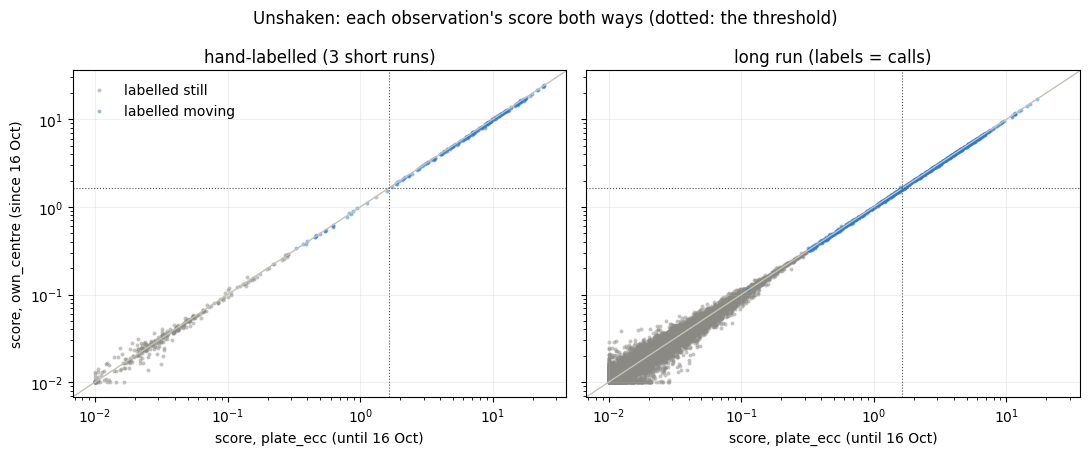

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (group, rows) in zip(axes, still.groupby("group")):
    for moving, colour, label in ((False, "#8a8984", "labelled still"), (True, "#2a78d6", "labelled moving")):
        part = rows[rows["moving"] == moving]
        ax.scatter(part["plate_ecc"].clip(lower=1e-2), part["own_centre"].clip(lower=1e-2), s=8, alpha=0.5, color=colour, label=label, linewidths=0)
    ax.axline((1, 1), (10, 10), color="#c3c2b7", lw=1)
    ax.axvline(THRESHOLD, color="#52514e", lw=0.8, ls=":")
    ax.axhline(THRESHOLD, color="#52514e", lw=0.8, ls=":")
    ax.set(xscale="log", yscale="log", title=group, xlabel="score, plate_ecc (until 16 Oct)")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("score, own_centre (since 16 Oct)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Unshaken: each observation's score both ways (dotted: the threshold)")
plt.tight_layout()

## 2. How well each method measures the shake

For every observation, the largest distance over its frames between the shift a method moved the patch back by and the shake that was made (both from the first frame), in pixels. `none` misses the whole shake. A mite labelled moving has legs that pull its own measurement along; the plate's median doesn't follow any one mite.

The miss is measured against the synthetic shake only, so it also holds any real movement of the plate. Unshaken, the plate of the long run moved by up to 0.26 px within a recording (0.23 px at the 95th percentile of its 295 recordings; the three short runs 0.02 px at most), and the two plate methods measured the same (correlation 0.999 between them). That is the floor of about 0.22 px every stabilized method shows below: what is left is the difference between methods.

In [4]:
miss = table.melt(id_vars=["shake", "moving"], value_vars=[f"miss_{m}" for m in METHODS], var_name="method", value_name="miss")
miss["method"] = miss["method"].str.removeprefix("miss_")
summary = (miss.groupby(["moving", "shake", "method"], observed=True)["miss"]
           .quantile([0.5, 0.95, 0.999]).unstack().rename(columns={0.5: "median", 0.95: "95%", 0.999: "99.9%"}))
summary.index = summary.index.set_levels(["labelled still", "labelled moving"], level=0)
display(summary.unstack("method")["95%"][METHODS].rename_axis(columns="95th percentile of the miss (px)"))
display(summary.unstack("method")["99.9%"][METHODS].rename_axis(columns="99.9th percentile of the miss (px)"))

95th percentile of the miss (px)   none  plate_ecc  plate_centre  own_centre  own_ecc
moving          shake                                                                
labelled still  still             0.000      0.233         0.214       0.218    0.238
                rigid 0.5 px      2.305      0.227         0.222       0.232    0.227
                rigid 1 px        4.500      0.223         0.226       0.233    0.227
                rigid 2 px        8.493      0.227         0.219       0.252    0.229
                per plate 1 px    4.528      4.683         4.639       0.233    0.226
                per plate 2 px    9.014      9.218         9.207       0.252    0.228
labelled moving still             0.000      0.150         0.136       0.204    0.204
                rigid 0.5 px      2.372      0.141         0.138       0.219    0.194
                rigid 1 px        4.423      0.136         0.143       0.218    0.193
                rigid 2 px        8.750      0.143         0.139       0.239    0.191
                per plate 1 px    4.743      4.922         4.941       0.218    0.194
                per plate 2 px    9.464      9.940         9.817       0.240    0.195

99.9th percentile of the miss (px)    none  plate_ecc  plate_centre  own_centre  own_ecc
moving          shake                                                                   
labelled still  still                0.000      0.260         0.240       0.262    0.280
                rigid 0.5 px         2.761      0.249         0.260       0.288    0.271
                rigid 1 px           6.052      0.249         0.253       0.293    0.273
                rigid 2 px          11.068      0.249         0.275       0.468    7.815
                per plate 1 px       6.055      6.921         6.770       0.307    0.275
                per plate 2 px      11.350     12.055        11.994       0.470   38.475
labelled moving still                0.000      0.241         0.226       0.341    0.323
                rigid 0.5 px         2.761      0.234         0.245       0.355    0.313
                rigid 1 px           5.460      0.234         0.239       0.362    0.307
                rigid 2 px          11.068      0.239         0.243       0.446    0.337
                per plate 1 px       6.152      6.983         6.968       0.351    0.288
                per plate 2 px      11.774     12.032        11.780       0.733   11.454

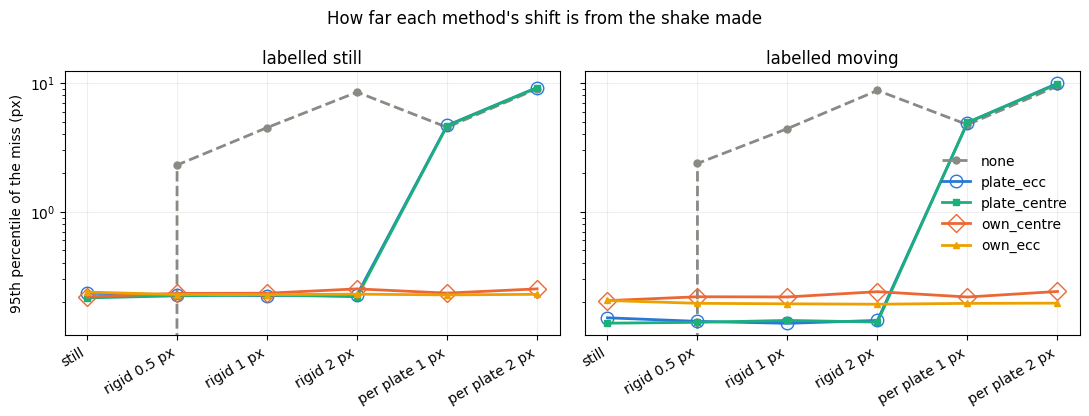

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
x = np.arange(len(SHAKE_ORDER))
for ax, moving in zip(axes, (False, True)):
    for m in METHODS:
        ys = summary.loc[("labelled moving" if moving else "labelled still", slice(None), m), "95%"].values
        ax.plot(x, ys, marker=MARKER[m], ms=SIZE[m], mfc="none" if SIZE[m] > 5 else None, lw=2, color=COLOURS[m], ls=STYLE.get(m, "-"), label=m)
    ax.set(yscale="log", title="labelled moving" if moving else "labelled still", xticks=x)
    ax.set_xticklabels(SHAKE_ORDER, rotation=30, ha="right")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("95th percentile of the miss (px)")
axes[1].legend(frameon=False, loc="center right")
fig.suptitle("How far each method's shift is from the shake made")
plt.tight_layout()

## 3. The calls under shake

Each method at the app's threshold (calibrated unshaken with `plate_ecc`) and at its own best threshold (also unshaken). On the hand-labelled runs, against the labels; on the long run, mostly the still recordings that get called moving. `flipped` is label-free: how many calls differ from the same method's call on the unshaken recording.

In [6]:
KEY = ["dataset", "mite", "recording"]

def shaken_calls(rows, own=False):
    base = rows[rows["shake"] == "still"].set_index(KEY)
    out = []
    for shake in SHAKE_ORDER:
        part = rows[rows["shake"] == shake].set_index(KEY)
        for m in METHODS:
            threshold = OWN_THRESHOLD[m] if own else THRESHOLD
            flipped = int(((part[m] >= threshold) != (base.loc[part.index, m] >= threshold)).sum())
            out.append({"shake": shake, "method": m, "AUC": calibration.auc(part[m], part["moving"]),
                        **calls(part, m, threshold), "flipped": flipped})
    return pd.DataFrame(out).set_index(["shake", "method"])

results = {(group, own): shaken_calls(rows, own) for group, rows in table.groupby("group") for own in (False, True)}
for (group, own), frame in results.items():
    print(f"{group}, {'each method at its own best threshold' if own else f'threshold {THRESHOLD} (the app)'}")
    display(frame.unstack("method").swaplevel(axis=1)[[(m, c) for m in METHODS for c in ("accuracy", "still called moving", "moving called still", "flipped")]]
            if not group.startswith("long") else frame.unstack("method").swaplevel(axis=1)[[(m, c) for m in METHODS for c in ("still called moving", "moving called still", "flipped")]])

hand-labelled (3 short runs), threshold 1.638 (the app)


method             none                                                 plate_ecc                                                 plate_centre  \
               accuracy still called moving moving called still flipped  accuracy still called moving moving called still flipped     accuracy   
shake                                                                                                                                            
per plate 1 px    0.893                  16                  39      33     0.872                  24                  42      44        0.874   
per plate 2 px    0.480                 243                  25     280     0.458                 251                  28     289        0.452   
rigid 0.5 px      0.942                   0                  30       8     0.940                   0                  31       9        0.938   
rigid 1 px        0.901                  12                  39      31     0.940                   0                  31       9        0.940   
rigid 2 px        0.497                 238                  21     273     0.940                   0                  31       9        0.940   
still             0.957                   0                  22       0     0.957                   0                  22       0        0.957   

method                                                         own_centre                                                  own_ecc                      \
               still called moving moving called still flipped   accuracy still called moving moving called still flipped accuracy still called moving   
shake                                                                                                                                                    
per plate 1 px                  24                  41      43      0.938                   0                  32      10    0.940                   0   
per plate 2 px                 253                  29     292      0.940                   0                  31       9    0.938                   2   
rigid 0.5 px                     0                  32      10      0.940                   0                  31       9    0.938                   0   
rigid 1 px                       0                  31       9      0.940                   0                  31       9    0.940                   0   
rigid 2 px                       0                  31       9      0.940                   0                  31       9    0.940                   0   
still                            0                  22       0      0.957                   0                  22       0    0.957                   0   

method                                      
               moving called still flipped  
shake                                       
per plate 1 px                  31       9  
per plate 2 px                  30      12  
rigid 0.5 px                    32      10  
rigid 1 px                      31       9  
rigid 2 px                      31       9  
still                           22       0

hand-labelled (3 short runs), each method at its own best threshold


method             none                                                 plate_ecc                                                 plate_centre  \
               accuracy still called moving moving called still flipped  accuracy still called moving moving called still flipped     accuracy   
shake                                                                                                                                            
per plate 1 px    0.584                 206                   8     213     0.583                 208                   7     214        0.575   
per plate 2 px    0.439                 287                   2     288     0.447                 285                   0     284        0.447   
rigid 0.5 px      0.783                 108                   4     111     0.990                   2                   3       4        0.990   
rigid 1 px        0.602                 200                   5     204     0.990                   1                   4       4        0.988   
rigid 2 px        0.441                 287                   1     287     0.988                   2                   4       5        0.988   
still             0.998                   1                   0       0     0.998                   1                   0       0        0.998   

method                                                         own_centre                                                  own_ecc                      \
               still called moving moving called still flipped   accuracy still called moving moving called still flipped accuracy still called moving   
shake                                                                                                                                                    
per plate 1 px                 211                   8     218      0.986                   2                   5       6    0.986                   2   
per plate 2 px                 285                   0     284      0.984                   3                   5       7    0.981                   5   
rigid 0.5 px                     2                   3       4      0.988                   1                   5       5    0.988                   1   
rigid 1 px                       2                   4       5      0.986                   2                   5       6    0.990                   1   
rigid 2 px                       2                   4       5      0.986                   2                   5       6    0.988                   2   
still                            1                   0       0      0.998                   1                   0       0    0.998                   1   

method                                      
               moving called still flipped  
shake                                       
per plate 1 px                   5       6  
per plate 2 px                   5       9  
rigid 0.5 px                     5       5  
rigid 1 px                       4       4  
rigid 2 px                       4       5  
still                            0       0

long run (labels = calls), threshold 1.638 (the app)


method                        none                                       plate_ecc                                    plate_centre                      \
               still called moving moving called still flipped still called moving moving called still flipped still called moving moving called still   
shake                                                                                                                                                    
per plate 1 px                 909                 433    1029                 921                 435    1039                 878                 439   
per plate 2 px                7393                 286    7658                7532                 263    7802                7360                 269   
rigid 0.5 px                   143                 445     237                   0                 449      82                   0                 449   
rigid 1 px                     914                 435    1030                   0                 445      78                   0                 446   
rigid 2 px                    7426                 288    7709                   0                 441      74                   0                 441   
still                            0                 361       0                   0                 367       0                   0                 366   

method                          own_centre                                         own_ecc                              
               flipped still called moving moving called still flipped still called moving moving called still flipped  
shake                                                                                                                   
per plate 1 px     993                   0                 447      80                   0                 446      79  
per plate 2 px    7627                   0                 448      81                  55                 446     136  
rigid 0.5 px        83                   0                 450      83                   0                 448      81  
rigid 1 px          80                   0                 446      79                   0                 446      79  
rigid 2 px          75                   0                 446      79                  17                 445      95  
still                0                   0                 367       0                   0                 367       0

long run (labels = calls), each method at its own best threshold


method                        none                                       plate_ecc                                    plate_centre                      \
               still called moving moving called still flipped still called moving moving called still flipped still called moving moving called still   
shake                                                                                                                                                    
per plate 1 px                4193                  54    4202                4002                  76    4076                3878                  76   
per plate 2 px               14620                  21   14592               14163                  25   14186               14096                  24   
rigid 0.5 px                  1376                  60    1391                   2                  52      54                   3                  53   
rigid 1 px                    4258                  69    4284                   2                  55      57                   2                  55   
rigid 2 px                   14702                  22   14675                   3                  53      56                   5                  54   
still                           50                   1       0                   1                   1       0                   2                   1   

method                          own_centre                                         own_ecc                              
               flipped still called moving moving called still flipped still called moving moving called still flipped  
shake                                                                                                                   
per plate 1 px    3955                   1                  59      59                   0                  56      56  
per plate 2 px   14119                   4                  60      63                  57                  58     115  
rigid 0.5 px        57                   2                  61      62                   1                  55      56  
rigid 1 px          58                   2                  58      59                   2                  56      58  
rigid 2 px          60                   4                  58      61                  24                  58      82  
still                0                   0                   1       0                   1                   1       0

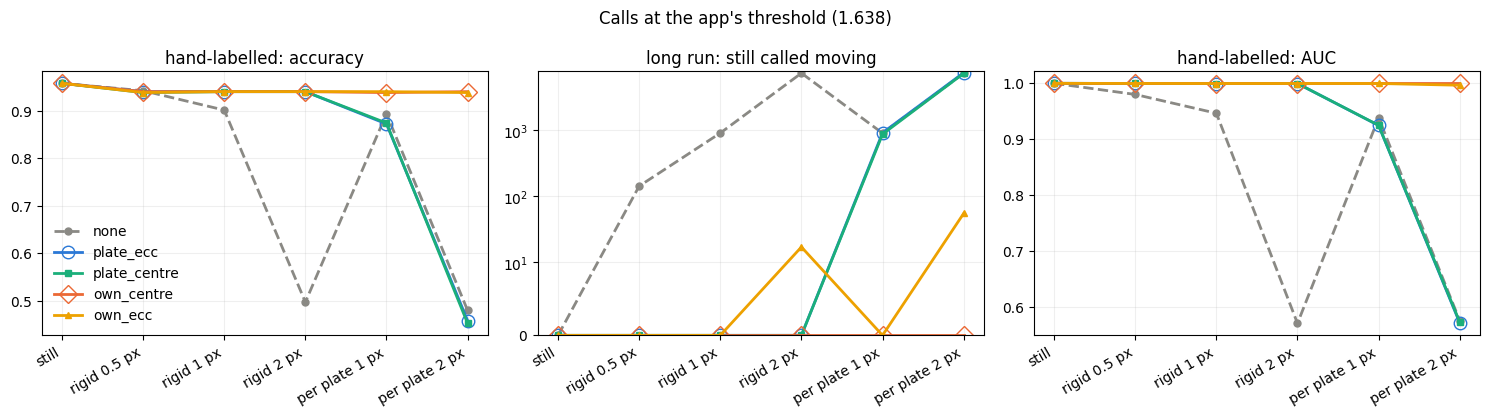

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
panels = [("hand-labelled (3 short runs)", "accuracy", "hand-labelled: accuracy"),
          ("long run (labels = calls)", "still called moving", "long run: still called moving"),
          ("hand-labelled (3 short runs)", "AUC", "hand-labelled: AUC")]
for ax, (group, column, title) in zip(axes, panels):
    frame = results[group, False]
    for m in METHODS:
        ax.plot(x, frame.xs(m, level="method")[column].values, marker=MARKER[m], ms=SIZE[m], mfc="none" if SIZE[m] > 5 else None, lw=2,
                color=COLOURS[m], ls=STYLE.get(m, "-"), label=m)
    ax.set(title=title, xticks=x)
    ax.set_xticklabels(SHAKE_ORDER, rotation=30, ha="right")
    ax.grid(alpha=0.2)
axes[1].set_yscale("symlog", linthresh=10)
axes[1].set_ylim(bottom=0)
axes[0].legend(frameon=False)
fig.suptitle(f"Calls at the app's threshold ({THRESHOLD})")
plt.tight_layout()

## 4. What a mite's own centre costs on real recordings

Unshaken, the plate didn't move (or barely), so whatever a mite's own shift does that the plate's doesn't is its own: its legs or body pulling its centre along, or a neighbour walking through its patch. `stray` is the largest distance over the frames between a mite's own shift and the plate's (the median of all mites'), for each way of measuring.

In [8]:
stray = still.groupby(["group", "moving"])[["stray_centre", "stray_ecc"]].quantile([0.5, 0.95, 0.99, 1.0]).unstack()
stray.index = stray.index.set_levels(["still", "moving"], level=1)
stray

stray_centre                      stray_ecc                     
                                            0.50   0.95   0.99   1.00      0.50   0.95   0.99   1.00
group                        moving                                                                 
hand-labelled (3 short runs) still         0.030  0.046  0.058  0.061     0.034  0.044  0.056  0.062
                             moving        0.132  0.232  0.326  0.347     0.111  0.213  0.250  0.261
long run (labels = calls)    still         0.030  0.048  0.058  0.091     0.032  0.044  0.051  0.088
                             moving        0.065  0.152  0.199  0.234     0.068  0.145  0.181  0.224

In [9]:
changed = still[(still["own_centre"] >= THRESHOLD) != (still["plate_ecc"] >= THRESHOLD)]
print(f"{len(changed)} of {len(still)} unshaken calls differ between own_centre and plate_ecc")
changed[["dataset", "mite", "recording", "moving", "plate_ecc", "own_centre", "stray_centre", "stray_ecc"]].sort_values("stray_centre", ascending=False).head(25)

8 of 17829 unshaken calls differ between own_centre and plate_ecc


,dataset,mite,recording,moving,plate_ecc,own_centre,stray_centre,stray_ecc
20168,test_run_2026-09-08_Mathis_last_dsRNA,10.5,55,True,1.713,1.636,0.205,0.179
3503,test_run_2026-09-08_Mathis_last_dsRNA,9.5,7,True,1.626,1.648,0.131,0.129
2130,test_run_2026-09-08_Mathis_last_dsRNA,12.5,3,True,1.583,1.666,0.126,0.120
1086,test_run_2026-09-08_Mathis_last_dsRNA,12.5,0,True,1.638,1.659,0.111,0.106
16669,test_run_2026-09-08_Mathis_last_dsRNA,6.8,45,True,1.662,1.603,0.093,0.077
18415,test_run_2026-09-08_Mathis_last_dsRNA,9.1,50,True,1.668,1.587,0.086,0.100
9032,test_run_2026-09-08_Mathis_last_dsRNA,6.3,23,True,1.644,1.618,0.082,0.075
31038,test_run_2026-09-08_Mathis_last_dsRNA,7.4,86,True,1.631,1.640,0.053,0.072


## 5. Speed

The stabilizer's own cost in an analysis: measuring every mite's shift in a recording, ECC (until 16 October) against the centre (since), with one cut and score of every mite for scale. Timed here in one process on sample_data's six recordings (30 mites, 10 frames each), best of three. (The benchmark run's own timings are not used: its processes shared the laptop with OneDrive and another job and were slowed for most of the run.)

In [10]:
import time
from classes.analyzer import Analyzer
from classes.plate_stabilizer import PlateStabilizer
from centre_stabilization import _dataset, centre_shifts, ecc_shifts

_ds, loader, mites, _labels = _dataset("sample_data")
recordings = [{mite_id: loader.read_mite(name, number) for mite_id, _zone, number, _box in mites} for name in loader.recording_names]
params = get_default_config().mite.params_for(METRIC)
pad = Analyzer.roi_padding(METRIC, params)
def best_of(work, repeat=3):
    times = []
    for _ in range(repeat):
        t = time.perf_counter()
        for crops in recordings:
            work(crops)
        times.append(time.perf_counter() - t)
    return min(times) / (len(recordings) * len(mites)) * 1000  # ms per mite and recording

def score_all(crops):
    for mite_id, _zone, _number, box in mites:
        Analyzer._motion_score(PlateStabilizer.cut(crops[mite_id], box, pad, np.zeros((len(crops[mite_id]), 2))), METRIC, params)

speed = pd.Series({
    "ECC shift (until 16 October)": best_of(lambda crops: [ecc_shifts(crops[m], box) for m, _z, _n, box in mites]),
    "centre shift (since)": best_of(lambda crops: [centre_shifts(crops[m], box) for m, _z, _n, box in mites]),
    "cut and score": best_of(score_all),
}, name="ms per mite and recording")
speed.to_frame().assign(**{"relative to the centre": speed / speed["centre shift (since)"]})

,ms per mite and recording,relative to the centre
ECC shift (until 16 October),15.050,17.728
centre shift (since),0.849,1.000
cut and score,5.758,6.783


## Findings

*Acted on: since 16 October 2026 the app stabilizes each mite by its own centre (`classes/plate_stabilizer.py`).*

From the run saved in this notebook (16 October 2026, OpenCV 4.12): the four recording folders with ground truth, 145 mites, 17 829 labelled observations, 1 068 of them moving; `outline_variability` at the default threshold 1.638 and at each method's own best threshold.

**Yes: on a plate that shakes as one piece, each mite's own centre works as well as the plate's shift, and it also copes when the plates shake separately, which the plate's shift doesn't.**

**Without shake, the two give the same calls.**
- 8 of 17 829 calls change between `own_centre` and `plate_ecc`. All 8 are on the long run, all labelled moving, and both scores are within 0.08 of the threshold.
- The median score moves by 0.003 to 0.005. AUC and accuracy are the same on both groups.
- For a mite labelled still, its own centre stays with the plate: 0.03 px from the plate's shift in the median, 0.09 px at most. For a moving mite, its legs pull its centre 0.07 to 0.13 px off in the median and 0.35 px at most. That is where the 8 changed calls come from.

**On a rigid shake of 0.5 to 2 px, the calls match `plate_ecc`.**
- At the app's threshold, both call no still recording of the long run moving, at every shake. They are far from `none`, which calls 143, 914 and 7 426 still recordings moving at 0.5, 1 and 2 px.
- Both flip about 80 calls of the long run at every shake. That floor comes from resampling the frames to make the synthetic shake, not from the shake itself: it doesn't grow with the shake and is the same for every method.
- At each method's own best threshold, `own_centre` makes 1 to 2 more errors out of 515 on the hand-labelled runs (accuracy 0.986 to 0.988 against 0.988 to 0.990). On the long run, 3 to 9 more of its 843 moving recordings are called still (58 to 61 against 52 to 55). The long run's labels are `plate_ecc`'s calls, so that comparison favours `plate_ecc` by construction.
- `own_centre` measures the shake a little less exactly than the median over 59 mites. At the 95th percentile, still mites are 0.23 to 0.25 px off against 0.22 to 0.23 px; moving mites are 0.22 to 0.24 px off against 0.14 px. At the 99.9th percentile with a 2 px shake: 0.47 px against 0.25 px. None of this shows in the calls.

**When the plates shake separately (one shake per plate), only the per-mite methods hold.**
- `plate_ecc` and `plate_centre` do as badly as no stabilization. On the long run they call 921 (1 px) and 7 532 (2 px) still recordings moving; on the hand-labelled runs accuracy falls to 0.87 and 0.46.
- `own_centre` doesn't change: it calls no still recording moving and keeps an accuracy of 0.94. The backup branch's `plate_shake.ipynb` saw the zones of the long run move apart by up to 0.85 px once, so this case is real, if rare.
- `own_ecc` holds up to 1 px, but at 2 px ECC sometimes runs off: up to 38 px wrong at the 99.9th percentile. It then calls 17 still recordings moving with a rigid 2 px shake and 55 with a per-plate 2 px shake. This confirms the 14 October benchmark: of the per-mite measurements, the centre is the one to use.

**The centre is much cheaper.**
- In one process, measuring a mite's centre shift takes about a nineteenth of the time phase correlation + ECC takes (0.5 against 9.7 ms per mite and recording on a quiet laptop; the cell above shows the run at hand). Measuring by ECC took 2.4 times as long as cutting and scoring the patch.
- So most of the scoring time went into measuring the plate's shift. With the centre, cutting, measuring and scoring a mite takes about a third of what it took (4.6 against 13.8 ms on the quiet laptop). Decoding the frames and the other per-mite work (MiteLook) come on top in both cases.

**What this doesn't test.**
- **Something other than the plate moving in a mite's patch:** a neighbour walking through it, or a mite that comes unglued and slides or turns. A mite's own centre follows these and the plate's median doesn't. The backup branch's `per_mite_stabilization.ipynb` (section 4) found such cases in the long run and proposed a fallback: use the plate's shift where a mite's own shift strays from it by more than a limit. This report gives a scale for that limit: still mites stray at most 0.09 px, moving ones at most 0.35 px.
- **Real shakes:** the shakes here are pure translations in quarter pixels. A real shake can also blur or rotate the image.
- **Only `outline_variability`:** it re-centres each frame on the mite itself, which may make it more forgiving of a stabilizer's small errors than another score would be.

**Two side notes.**
- On these datasets, the per-mite centre method shows no regression against the plate's shift. Whatever made the results of 14 October look worse, it doesn't show here.
- The default threshold, 1.638, is far above the best threshold for the labels (0.31 for every method). Even unshaken, 22 of the 225 hand-labelled moving recordings are called still at 1.638 (accuracy 0.957 against 0.998). This is separate from stabilization and the same for every method, but worth a look.